# Lab 3 — Kiểm thử, benchmark và đánh giá (RSA-OAEP & Hybrid)

Notebook này **chạy toàn bộ** quy trình đánh giá của `rsatool` và ghi mọi kết quả vào `Output/<OS>/` (`ubuntu` hoặc `windows`):

| Thư mục | Nội dung |
|---|---|
| `Output/<OS>/logs/` | log `ctest`, `--kat`, CLI demo/negative tests, benchmark |
| `Output/<OS>/csv/` | `hardware`, `kat_summary`, `cli_tests`, `bench_<os>_<compiler>.csv`, bảng phân tích |
| `Output/<OS>/plots/` | đồ thị PNG (có error bar CI 95%) |
| `Output/<OS>/analysis.md` | bảng + nhận xét tự sinh, dùng chép vào báo cáo |
| `Output/<OS>/work/` | khoá/tệp thử nghiệm tạm (chỉ là **test keys**) |

**Cách dùng:** build `rsatool` trước (`build_<os>_<compiler>/`), rồi `Run All`. Chạy lại notebook trên máy kia (Windows/Ubuntu) để có dữ liệu so sánh chéo OS ở mục 8.
Đặt `QUICK = True` để chạy thử nhanh; để nộp bài dùng `QUICK = False` (N ≥ 30, warm-up 1 s, 1 KiB / 1 MiB / 100 MiB).

In [5]:
import os, sys, json, platform, shutil, subprocess, time, base64, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt 

QUICK = False                 # True = thử nhanh (ít lượt); False = đúng protocol của lab
BUILD_DIR_OVERRIDE = "build_windows_msvc"     # vd "build_ubuntu_gcc"; None = tự dò build_<os>_*

ROOT = Path.cwd()
if not (ROOT / "CMakeLists.txt").exists():
    ROOT = ROOT.parent
assert (ROOT / "CMakeLists.txt").exists(), "Hãy mở notebook từ lab3/ hoặc lab3/notebooks/"

IS_WIN = platform.system() == "Windows"
OS_NAME = "windows" if IS_WIN else "ubuntu"
EXE = ".exe" if IS_WIN else ""

OUT = ROOT / "Output" / OS_NAME
LOGS, CSV, PLOTS, WORK = (OUT / d for d in ("logs", "csv", "plots", "work"))
for d in (LOGS, CSV, PLOTS, WORK):
    d.mkdir(parents=True, exist_ok=True)

def find_binary():
    dirs = [ROOT / BUILD_DIR_OVERRIDE] if BUILD_DIR_OVERRIDE else sorted(ROOT.glob(f"build_{OS_NAME}_*"))
    for d in dirs:
        for sub in (".", "Release", "bin"):
            p = d / sub / f"rsatool{EXE}"
            if p.exists():
                return d, p
    p = ROOT / "release" / OS_NAME / f"rsatool{EXE}"
    if p.exists():
        return None, p
    raise FileNotFoundError(f"Không thấy rsatool{EXE}. Build trước: scripts/build_*.{'bat' if IS_WIN else 'sh'}")

BUILD_DIR, BIN = find_binary()
COMPILER = BUILD_DIR.name.split("_")[-1] if BUILD_DIR else "prebuilt"
BENCH_CSV = CSV / f"bench_{OS_NAME}_{COMPILER}.csv"
print("OS      :", OS_NAME)
print("Binary  :", BIN)
print("Compiler:", COMPILER)
print("Output  :", OUT)

def run(cmd, log=None, cwd=None, timeout=None, append=False):
    """Chạy lệnh, ghi log vào Output/<OS>/logs, trả (rc, stdout, stderr)."""
    cmd = [str(c) for c in cmd]
    t0 = time.perf_counter()
    try:
        p = subprocess.run(cmd, cwd=cwd, capture_output=True, timeout=timeout)
        rc, out, err = p.returncode, p.stdout.decode("utf-8", "replace"), p.stderr.decode("utf-8", "replace")
    except FileNotFoundError as e:
        rc, out, err = 127, "", str(e)
    dt = time.perf_counter() - t0
    if log:
        with open(LOGS / log, "a" if append else "w", encoding="utf-8") as f:
            f.write("$ " + " ".join(cmd) + "\n[rc=%d] [%.2fs]\n--- stdout ---\n%s\n--- stderr ---\n%s\n\n" % (rc, dt, out, err))
    return rc, out, err

def md_table(df, floatfmt=".3f"):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(format(v, floatfmt) if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lines)

OS      : windows
Binary  : d:\UIT\NT219\crypto-labs\lab3\build_windows_msvc\Release\rsatool.exe
Compiler: msvc
Output  : d:\UIT\NT219\crypto-labs\lab3\Output\windows


## 1. Thông tin phần cứng / môi trường
Bảng này dùng cho mục "Hardware/OS table" của báo cáo. Hãy tự bổ sung compiler flags, storage và CPU governor.

In [6]:
def cpu_model():
    try:
        if IS_WIN:
            return subprocess.check_output(
                ["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name"], text=True).strip()
        for line in open("/proc/cpuinfo", encoding="utf-8"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or "unknown"

def ram_gb():
    try:
        import psutil
        return round(psutil.virtual_memory().total / 2**30, 1)
    except Exception:
        pass
    try:
        if not IS_WIN:
            for line in open("/proc/meminfo", encoding="utf-8"):
                if line.startswith("MemTotal"):
                    return round(int(line.split()[1]) / 2**20, 1)
    except Exception:
        pass
    return None

hw = {
    "os": OS_NAME, "os_version": platform.platform(), "cpu": cpu_model(),
    "logical_cpus": os.cpu_count(), "ram_gb": ram_gb(), "python": platform.python_version(),
    "compiler_build_dir": COMPILER, "binary": str(BIN),
    "timestamp_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "quick_mode": QUICK,
}
(CSV / "hardware.json").write_text(json.dumps(hw, indent=2), encoding="utf-8")
pd.DataFrame([hw]).T.rename(columns={0: "value"})

,value
os,windows
os_version,Windows-10-10.0.19045-SP0
cpu,Intel(R) Core(TM) i7-8565U CPU @ 1.80GHz
logical_cpus,8
ram_gb,15.8
python,3.14.7
compiler_build_dir,msvc
binary,d:\UIT\NT219\crypto-labs\lab3\build_windows_ms...
timestamp_utc,2026-11-07T07:58:09Z
quick_mode,False


## 2. Unit tests (ctest)

In [7]:
if BUILD_DIR and shutil.which("ctest"):
    rc, out, err = run(["ctest", "--output-on-failure", "-C", "Release"], "ctest.log", cwd=BUILD_DIR)
    print("\n".join(out.strip().splitlines()[-12:]))
    CTEST_OK = (rc == 0)
else:
    CTEST_OK = None
    print("Bỏ qua ctest (không có build dir hoặc không có ctest trong PATH).")
print("ctest passed:", CTEST_OK)

      Start 21: 7. Malformed encodings are rejected
21/24 Test #21: 7. Malformed encodings are rejected ...........................................   Passed    0.01 sec
      Start 22: 8. Corrupted / wrong-type key files are rejected
22/24 Test #22: 8. Corrupted / wrong-type key files are rejected ..............................   Passed    0.34 sec
      Start 23: 9. Decrypt errors are generic (no oracle by message)
23/24 Test #23: 9. Decrypt errors are generic (no oracle by message) ..........................   Passed    0.35 sec
      Start 24: kat_runner
24/24 Test #24: kat_runner ....................................................................   Passed    0.46 sec

100% tests passed, 0 tests failed out of 24

Total Test time (real) =   4.94 sec
ctest passed: True


## 3. Known Answer Tests (`--kat`)

In [8]:
rc, out, err = run([BIN, "--kat", ROOT / "tests" / "vectors" / "rsa_oaep_vectors.json", "--verbose"], "kat.log")
print(out)
rows = []
for line in out.splitlines():
    if line.startswith("[PASS]") or line.startswith("[FAIL]"):
        rows.append({"status": line[1:5], "case": line[7:].strip()})
kat_df = pd.DataFrame(rows)
kat_df.to_csv(CSV / "kat_summary.csv", index=False)
KAT_OK = (rc == 0)
print("KAT passed:", KAT_OK)
kat_df

[PASS] AES-256-GCM TC13 (empty plaintext)
[PASS] AES-256-GCM TC14 (16 zero bytes)
[PASS] AES-256-GCM TC16 (with AAD)
[PASS] RSA-3072 OAEP round-trip (empty message)
[PASS] RSA-3072 OAEP round-trip (32-byte key, label)
[PASS] RSA-3072 OAEP round-trip (max 318 bytes)
[PASS] Hybrid RSA-3072 round-trip 319 B (just above OAEP limit)
[PASS] Hybrid RSA-3072 round-trip 1 KiB with label
[PASS] Hybrid RSA-3072 round-trip 1 MiB
----------------------------------------
Total: 9  Passed: 9  Failed: 0

KAT passed: True


,status,case
0,PASS,AES-256-GCM TC13 (empty plaintext)
1,PASS,AES-256-GCM TC14 (16 zero bytes)
2,PASS,AES-256-GCM TC16 (with AAD)
3,PASS,RSA-3072 OAEP round-trip (empty message)
4,PASS,"RSA-3072 OAEP round-trip (32-byte key, label)"
5,PASS,RSA-3072 OAEP round-trip (max 318 bytes)
6,PASS,Hybrid RSA-3072 round-trip 319 B (just above O...
7,PASS,Hybrid RSA-3072 round-trip 1 KiB with label
8,PASS,Hybrid RSA-3072 round-trip 1 MiB


## 4. CLI demo + negative tests (end-to-end)
Mỗi test chạy `rsatool` thật. Với test âm, tiêu chí là **fail-closed**: exit code ≠ 0 **và không tạo file plaintext**.

In [9]:
(LOGS / "cli_demo.log").unlink(missing_ok=True)
for sub in ("k3072", "k4096", "other"):
    (WORK / sub).mkdir(exist_ok=True)

def cli(*a):
    return run([BIN, *a], "cli_demo.log", append=True)
def enc(inp, pub, out, *extra):
    return cli("encrypt", "--in", inp, "--pub", pub, "--out", out, *extra)
def dec(inp, priv, out, *extra):
    Path(out).unlink(missing_ok=True)
    return cli("decrypt", "--in", inp, "--priv", priv, "--out", out, *extra)
def fails_closed(rc, outfile):
    return rc != 0 and not Path(outfile).exists()
def w(name, data):
    p = WORK / name
    p.write_bytes(data)
    return p

results = []
def record(name, expected, ok, detail=""):
    results.append({"test": name, "expected": expected, "result": "PASS" if ok else "FAIL", "detail": detail})

PUB, PRIV = WORK / "k3072" / "pub.pem", WORK / "k3072" / "priv.pem"
PUB4, PRIV4 = WORK / "k4096" / "pub.pem", WORK / "k4096" / "priv.pem"
OPUB, OPRIV = WORK / "other" / "pub.pem", WORK / "other" / "priv.pem"

# --- Keygen ---
rc, _, _ = cli("keygen", "--bits", "3072", "--pub", PUB, "--priv", PRIV)
files = [WORK / "k3072" / f for f in ("pub.pem", "priv.pem", "pub.der", "priv.der", "keys_metadata.json")]
record("keygen RSA-3072", "rc=0, PEM+DER+metadata", rc == 0 and all(f.exists() for f in files), f"rc={rc}")
meta = json.loads((WORK / "k3072" / "keys_metadata.json").read_text()) if files[-1].exists() else {}
record("metadata JSON fields", "modulus_bits=3072, SHA-256, MGF1-SHA256",
       meta.get("modulus_bits") == 3072 and meta.get("hash") == "SHA-256" and meta.get("mgf") == "MGF1-SHA256", str(meta))
rc, _, _ = cli("keygen", "--bits", "4096", "--pub", PUB4, "--priv", PRIV4)
record("keygen RSA-4096", "rc=0", rc == 0, f"rc={rc}")
rc, _, _ = cli("keygen", "--bits", "3072", "--pub", OPUB, "--priv", OPRIV)
record("keygen second RSA-3072 (wrong-key tests)", "rc=0", rc == 0, f"rc={rc}")
rc, _, _ = cli("keygen", "--bits", "2048", "--pub", WORK / "p2048.pem", "--priv", WORK / "s2048.pem")
record("keygen RSA-2048 rejected", "rc=2 (unsupported size)", rc == 2, f"rc={rc}")

# --- Direct RSA-OAEP ---
msg_small = w("msg_small.bin", os.urandom(100))
rc1, _, _ = enc(msg_small, PUB, WORK / "ct_small.bin")
rc2, _, _ = dec(WORK / "ct_small.bin", PRIV, WORK / "dec_small.bin")
ok = rc1 == 0 and rc2 == 0 and (WORK / "dec_small.bin").read_bytes() == msg_small.read_bytes() \
     and (WORK / "ct_small.bin").stat().st_size == 384
record("direct RSA-OAEP round trip (100 B)", "ct=384 B, plaintext equal", ok, f"rc={rc1},{rc2}")

# --- Boundary 318 / 319 ---
m318 = w("m318.bin", os.urandom(318)); m319 = w("m319.bin", os.urandom(319))
enc(m318, PUB, WORK / "ct318.bin"); enc(m319, PUB, WORK / "ct319.bin")
direct = (WORK / "ct318.bin").exists() and (WORK / "ct318.bin").stat().st_size == 384
hybrid = (WORK / "ct319.bin").exists() and (WORK / "ct319.bin").read_bytes()[:1] == b"{"
record("318 B -> direct RSA-OAEP", "384-byte raw ciphertext", direct)
record("319 B -> automatic hybrid", "JSON envelope", hybrid)
r1, _, _ = dec(WORK / "ct318.bin", PRIV, WORK / "d318.bin"); r2, _, _ = dec(WORK / "ct319.bin", PRIV, WORK / "d319.bin")
record("318/319 B round trip", "plaintext equal",
       r1 == 0 and r2 == 0 and (WORK / "d318.bin").read_bytes() == m318.read_bytes() and (WORK / "d319.bin").read_bytes() == m319.read_bytes())

# --- Hybrid 1 MiB, RSA-4096 ---
big = w("big.bin", os.urandom(1 << 20))
enc(big, PUB, WORK / "big.env.json"); r, _, _ = dec(WORK / "big.env.json", PRIV, WORK / "big.dec")
record("hybrid round trip 1 MiB (RSA-3072)", "plaintext equal", r == 0 and (WORK / "big.dec").read_bytes() == big.read_bytes())
enc(big, PUB4, WORK / "big4.env.json"); r, _, _ = dec(WORK / "big4.env.json", PRIV4, WORK / "big4.dec")
record("hybrid round trip 1 MiB (RSA-4096)", "plaintext equal", r == 0 and (WORK / "big4.dec").read_bytes() == big.read_bytes())

# --- Encodings ---
for e in ("hex", "base64"):
    enc(msg_small, PUB, WORK / f"ct_{e}.txt", "--encode", e)
    r, _, _ = dec(WORK / f"ct_{e}.txt", PRIV, WORK / f"dec_{e}.bin", "--encode", e)
    record(f"--encode {e} round trip", "plaintext equal", r == 0 and (WORK / f"dec_{e}.bin").read_bytes() == msg_small.read_bytes())

# --- Negative: label ---
enc(msg_small, PUB, WORK / "ct_lbl.bin", "--label", "SECURE_CONTEXT")
rc, _, _ = dec(WORK / "ct_lbl.bin", PRIV, WORK / "o1.bin", "--label", "WRONG_CONTEXT")
record("wrong OAEP label (direct)", "fail-closed", fails_closed(rc, WORK / "o1.bin"), f"rc={rc}")
rc, _, _ = dec(WORK / "ct_lbl.bin", PRIV, WORK / "o2.bin")
record("missing OAEP label (direct)", "fail-closed", fails_closed(rc, WORK / "o2.bin"), f"rc={rc}")
enc(big, PUB, WORK / "env_lbl.json", "--label", "SECURE_CONTEXT")
rc, _, _ = dec(WORK / "env_lbl.json", PRIV, WORK / "o3.bin", "--label", "WRONG_CONTEXT")
record("wrong OAEP label (hybrid)", "fail-closed", fails_closed(rc, WORK / "o3.bin"), f"rc={rc}")

# --- Negative: wrong private key ---
rc, _, _ = dec(WORK / "ct_small.bin", OPRIV, WORK / "o4.bin")
record("wrong private key (direct)", "fail-closed", fails_closed(rc, WORK / "o4.bin"), f"rc={rc}")
rc, _, _ = dec(WORK / "big.env.json", OPRIV, WORK / "o5.bin")
record("wrong private key (hybrid)", "fail-closed", fails_closed(rc, WORK / "o5.bin"), f"rc={rc}")

# --- Negative: altered RSA ciphertext ---
ct = bytearray((WORK / "ct_small.bin").read_bytes()); ct[10] ^= 1
w("ct_flip.bin", bytes(ct))
rc, _, _ = dec(WORK / "ct_flip.bin", PRIV, WORK / "o6.bin")
record("altered RSA ciphertext (1 bit)", "fail-closed", fails_closed(rc, WORK / "o6.bin"), f"rc={rc}")

# --- Negative: tampered envelope ---
def tamper_env(src, dst, field, value=None):
    env = json.loads(Path(src).read_text(encoding="utf-8"))
    if value is None:
        raw = bytearray(base64.b64decode(env[field])); raw[0] ^= 1
        env[field] = base64.b64encode(bytes(raw)).decode()
    else:
        env[field] = value
    Path(dst).write_text(json.dumps(env), encoding="utf-8")

for field in ("ciphertext", "iv", "tag", "wrapped_key"):
    tamper_env(WORK / "big.env.json", WORK / f"env_{field}.json", field)
    rc, _, _ = dec(WORK / f"env_{field}.json", PRIV, WORK / f"o_{field}.bin")
    record(f"tampered envelope field '{field}'", "fail-closed", fails_closed(rc, WORK / f"o_{field}.bin"), f"rc={rc}")
for field, value in (("hash", "SHA-1"), ("mode", "XYZ"), ("rsa_modulus", 4096), ("label", "other")):
    tamper_env(WORK / "big.env.json", WORK / f"envh_{field}.json", field, value)
    rc, _, _ = dec(WORK / f"envh_{field}.json", PRIV, WORK / f"oh_{field}.bin")
    record(f"tampered envelope header '{field}'", "fail-closed", fails_closed(rc, WORK / f"oh_{field}.bin"), f"rc={rc}")
txt = (WORK / "big.env.json").read_text(encoding="utf-8")
w("env_trunc.json", txt[: len(txt) // 2].encode())
rc, _, _ = dec(WORK / "env_trunc.json", PRIV, WORK / "o_trunc.bin")
record("truncated envelope JSON", "fail-closed", fails_closed(rc, WORK / "o_trunc.bin"), f"rc={rc}")

# --- Negative: corrupted key file / unknown option ---
pem = (WORK / "k3072" / "pub.pem").read_bytes()
w("pub_trunc.pem", pem[: len(pem) // 2])
rc, _, _ = cli("encrypt", "--in", msg_small, "--pub", WORK / "pub_trunc.pem", "--out", WORK / "o_badkey.bin")
record("corrupted public key PEM", "rc!=0", rc != 0, f"rc={rc}")
rc, _, _ = cli("bogus-command")
record("unknown command", "rc=2", rc == 2, f"rc={rc}")

cli_df = pd.DataFrame(results)
cli_df.to_csv(CSV / "cli_tests.csv", index=False)
print(f"{(cli_df.result == 'PASS').sum()}/{len(cli_df)} CLI tests passed")
cli_df

30/30 CLI tests passed


,test,expected,result,detail
0,keygen RSA-3072,"rc=0, PEM+DER+metadata",PASS,rc=0
1,metadata JSON fields,"modulus_bits=3072, SHA-256, MGF1-SHA256",PASS,"{'creation_time': '2026-11-07T07:58:50Z', 'mod..."
2,keygen RSA-4096,rc=0,PASS,rc=0
3,keygen second RSA-3072 (wrong-key tests),rc=0,PASS,rc=0
4,keygen RSA-2048 rejected,rc=2 (unsupported size),PASS,rc=2
5,direct RSA-OAEP round trip (100 B),"ct=384 B, plaintext equal",PASS,"rc=0,0"
6,318 B -> direct RSA-OAEP,384-byte raw ciphertext,PASS,
7,319 B -> automatic hybrid,JSON envelope,PASS,
8,318/319 B round trip,plaintext equal,PASS,
9,hybrid round trip 1 MiB (RSA-3072),plaintext equal,PASS,


## 5. Benchmark
Chạy `rsatool bench` (RSA-3072/4096 keygen + OAEP enc/dec, AES-256-GCM, Hybrid 1 KiB / 1 MiB / 100 MiB).
Mỗi lượt đo là một block thao tác; thống kê gồm mean, median, std, **CI 95% (t-Student)**. Với `QUICK = False` bước này mất vài phút đến vài chục phút (RSA-4096 keygen + 100 MiB).

In [10]:
if QUICK:
    bench_args = ["bench", "--what", "all", "--bits", "both", "--runs", 5, "--keygen-runs", 5,
                  "--rsa-block", 10, "--warmup", 0.2, "--sizes", "1024,1048576", "--csv", BENCH_CSV]
else:
    bench_args = ["bench", "--what", "all", "--bits", "both", "--runs", 100, "--keygen-runs", 100,
                  "--rsa-block", 100, "--warmup", 1.0, "--csv", BENCH_CSV]
t0 = time.time()
rc, out, err = run([BIN, *bench_args], "bench.log")
print(out[:1800])
print(f"rc={rc}, elapsed={time.time() - t0:.0f}s, csv={BENCH_CSV}")
assert rc == 0 and BENCH_CSV.exists(), err

== System ==
OS        : Windows
Compiler  : MSVC 1951
OpenSSL   : OpenSSL 4.0.2 25 Aug 2026
HW threads: 8  (ghi thêm CPU model/RAM/governor vào báo cáo)
Protocol  : warm-up 1s, N=100 runs/case, RSA block=100 ops, hybrid block adaptive (<=1000 ops, ~128 MiB/run)
Throughput: 1 MB = 10^6 bytes. CI 95% = Student t.

cat     algo                  bits      size      metric        mean      median      stddev  95% CI
aes     AES-256-GCM enc          -     1 KiB     latency       0.001       0.001       0.000  [0.001, 0.001] ms/op
aes     AES-256-GCM enc          -     1 KiB  throughput     705.878     713.241      54.452  [694.988, 716.768] MB/s
aes     AES-256-GCM dec          -     1 KiB     latency       0.001       0.001       0.000  [0.001, 0.001] ms/op
aes     AES-256-GCM dec          -     1 KiB  throughput     777.520     769.231      71.166  [763.287, 791.753] MB/s
aes     AES-256-GCM enc          -     1 MiB     latency       0.616       0.619       0.030  [0.610, 0.622] ms/op
aes

## 6. Bảng thống kê

In [11]:
df = pd.read_csv(BENCH_CSV)
df["op"] = df["algo"].str.replace(r"^(RSA-\d+|Hybrid-\d+|AES-256-GCM)\s*", "", regex=True)
lat = df[df.metric == "latency"].copy()
thr = df[df.metric == "throughput"].copy()
SIZE_LABEL = {1024: "1 KiB", 1048576: "1 MiB", 104857600: "100 MiB"}
def size_lbl(n):
    return SIZE_LABEL.get(int(n), f"{int(n)} B") if n else "-"

cols = ["algo", "bits", "size", "n", "mean", "median", "stddev", "ci95_lo", "ci95_hi", "unit"]
tab = df.copy()
tab["size"] = tab["size_bytes"].map(size_lbl)
tab = tab[["category", "metric"] + cols]
tab.to_csv(CSV / "bench_table_all.csv", index=False)

rsa_tab = tab[(tab.category == "rsa")].drop(columns=["category", "metric"])
hyb_lat_tab = tab[(tab.category.isin(["hybrid", "aes"])) & (tab.metric == "latency")].drop(columns=["category", "metric"])
hyb_thr_tab = tab[(tab.category.isin(["hybrid", "aes"])) & (tab.metric == "throughput")].drop(columns=["category", "metric"])
print("RSA (ms/op)"); display(rsa_tab)
print("AES-GCM / Hybrid latency (ms/op)"); display(hyb_lat_tab)
print("AES-GCM / Hybrid throughput (MB/s)"); display(hyb_thr_tab)

RSA (ms/op)


,algo,bits,size,n,mean,median,stddev,ci95_lo,ci95_hi,unit
12,RSA-3072 keygen,3072,-,100,207.951958,169.714800,160.855475,175.780863,240.123053,ms/op
13,RSA-3072 OAEP enc,3072,32 B,100,0.067977,0.067558,0.002671,0.067443,0.068511,ms/op
14,RSA-3072 OAEP dec,3072,32 B,100,2.220477,2.101695,0.367831,2.146911,2.294043,ms/op
27,RSA-4096 keygen,4096,-,100,569.790406,462.597700,365.952995,496.599807,642.981005,ms/op
28,RSA-4096 OAEP enc,4096,32 B,100,0.095255,0.094153,0.006107,0.094034,0.096476,ms/op
29,RSA-4096 OAEP dec,4096,32 B,100,4.522551,4.376331,0.428978,4.436755,4.608347,ms/op


AES-GCM / Hybrid latency (ms/op)


,algo,bits,size,n,mean,median,stddev,ci95_lo,ci95_hi,unit
0,AES-256-GCM enc,0,1 KiB,100,0.001461,0.001436,0.000133,0.001434,0.001487,ms/op
2,AES-256-GCM dec,0,1 KiB,100,0.001331,0.001331,0.000159,0.001299,0.001363,ms/op
4,AES-256-GCM enc,0,1 MiB,100,0.615924,0.619497,0.030151,0.609894,0.621954,ms/op
6,AES-256-GCM dec,0,1 MiB,100,0.736605,0.712145,0.080467,0.720512,0.752699,ms/op
8,AES-256-GCM enc,0,100 MiB,100,66.166670,66.243700,1.607286,65.845213,66.488127,ms/op
10,AES-256-GCM dec,0,100 MiB,100,67.957759,66.317100,5.478661,66.862027,69.053491,ms/op
15,Hybrid-3072 enc,3072,1 KiB,100,0.075908,0.074894,0.003761,0.075156,0.076661,ms/op
17,Hybrid-3072 dec,3072,1 KiB,100,2.069880,1.985498,0.188116,2.032257,2.107503,ms/op
19,Hybrid-3072 enc,3072,1 MiB,100,0.710995,0.705765,0.019919,0.707012,0.714979,ms/op
21,Hybrid-3072 dec,3072,1 MiB,100,2.709914,2.644832,0.142045,2.681505,2.738323,ms/op


AES-GCM / Hybrid throughput (MB/s)


,algo,bits,size,n,mean,median,stddev,ci95_lo,ci95_hi,unit
1,AES-256-GCM enc,0,1 KiB,100,705.877959,713.241014,54.452109,694.987537,716.768381,MB/s
3,AES-256-GCM dec,0,1 KiB,100,777.519990,769.230774,71.166280,763.286734,791.753246,MB/s
5,AES-256-GCM enc,0,1 MiB,100,1706.375727,1692.624516,81.596361,1690.056455,1722.695000,MB/s
7,AES-256-GCM dec,0,1 MiB,100,1435.594696,1472.420211,114.697001,1412.655295,1458.534096,MB/s
9,AES-256-GCM enc,0,100 MiB,100,1585.719111,1582.906758,40.362485,1577.646614,1593.791608,MB/s
11,AES-256-GCM dec,0,100 MiB,100,1550.989314,1581.154884,101.244478,1530.740418,1571.238209,MB/s
16,Hybrid-3072 enc,3072,1 KiB,100,13.521169,13.672748,0.637923,13.393584,13.648754,MB/s
18,Hybrid-3072 dec,3072,1 KiB,100,0.498012,0.515740,0.036921,0.490627,0.505396,MB/s
20,Hybrid-3072 enc,3072,1 MiB,100,1475.843897,1485.729498,37.768226,1468.290252,1483.397543,MB/s
22,Hybrid-3072 dec,3072,1 MiB,100,387.909994,396.462210,18.717298,384.166535,391.653454,MB/s


## 7. Đồ thị (lưu vào `Output/<OS>/plots/`)

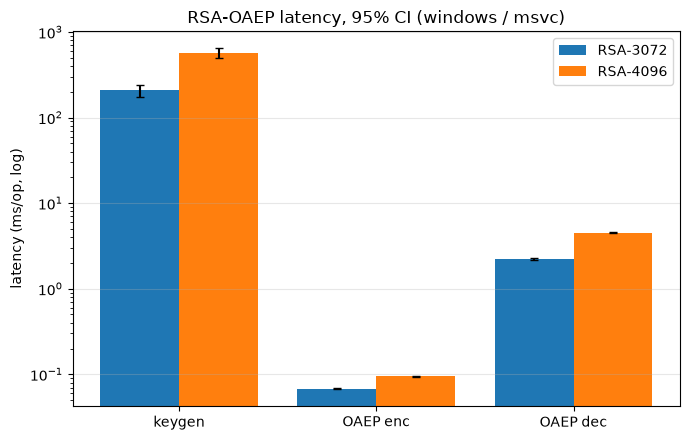

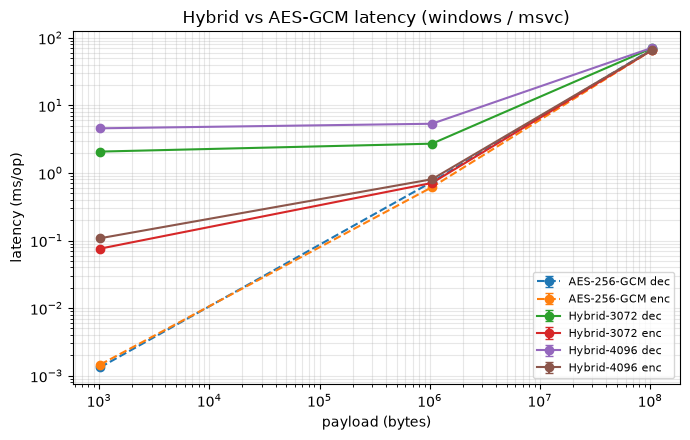

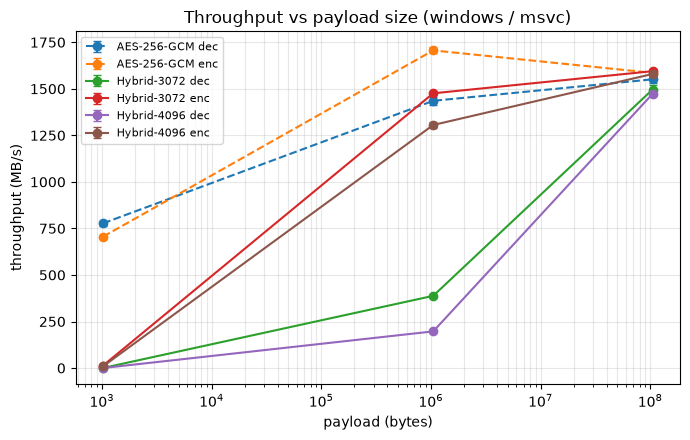

,bits,size,hybrid_ms,aes_gcm_ms,overhead_ms,hybrid_over_aes
0,3072,1 KiB,0.075908,0.001461,0.074448,51.967495
1,3072,1 MiB,0.710995,0.615924,0.095071,1.154356
2,3072,100 MiB,65.842823,66.166670,-0.323847,0.995106
3,4096,1 KiB,0.108138,0.001461,0.106678,74.032296
4,4096,1 MiB,0.806890,0.615924,0.190966,1.310048
5,4096,100 MiB,66.471254,66.166670,0.304584,1.004603


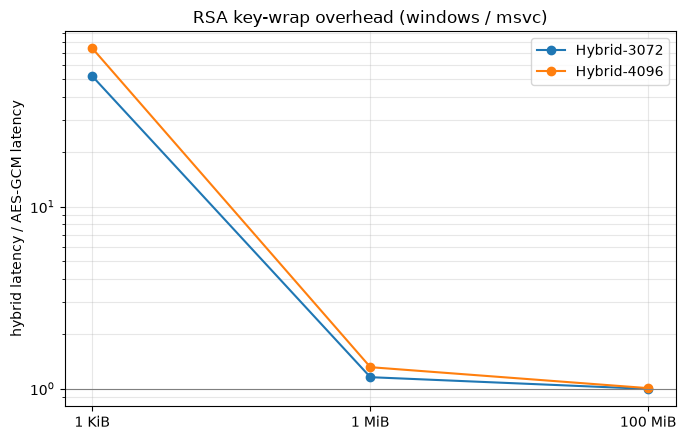

In [12]:
def yerr(d):
    return [np.clip(d["mean"] - d["ci95_lo"], 0, None), np.clip(d["ci95_hi"] - d["mean"], 0, None)]
def save(fig, name):
    fig.tight_layout(); fig.savefig(PLOTS / name, dpi=150); plt.show()
TITLE = f"{OS_NAME} / {COMPILER}"

# 7.1 RSA keygen / encrypt / decrypt: 3072 vs 4096
rsa = lat[lat.category == "rsa"]
if not rsa.empty:
    ops = ["keygen", "OAEP enc", "OAEP dec"]
    bits_list = sorted(rsa.bits.unique()); x = np.arange(len(ops)); width = 0.8 / len(bits_list)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, b in enumerate(bits_list):
        d = rsa[rsa.bits == b].set_index("op").reindex(ops)
        ax.bar(x + i * width, d["mean"], width, yerr=yerr(d), capsize=3, label=f"RSA-{b}")
    ax.set_xticks(x + width * (len(bits_list) - 1) / 2); ax.set_xticklabels(ops)
    ax.set_yscale("log"); ax.set_ylabel("latency (ms/op, log)"); ax.set_title(f"RSA-OAEP latency, 95% CI ({TITLE})")
    ax.legend(); ax.grid(axis="y", alpha=.3)
    save(fig, "rsa_latency_3072_vs_4096.png")

# 7.2 Hybrid / AES-GCM latency vs size
fig, ax = plt.subplots(figsize=(7, 4.5))
for (cat, bits, op), d in lat[lat.category.isin(["hybrid", "aes"])].groupby(["category", "bits", "op"]):
    d = d.sort_values("size_bytes")
    label = f"AES-256-GCM {op}" if cat == "aes" else f"Hybrid-{bits} {op}"
    ax.errorbar(d["size_bytes"], d["mean"], yerr=yerr(d), marker="o", capsize=3, ls="--" if cat == "aes" else "-", label=label)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("payload (bytes)"); ax.set_ylabel("latency (ms/op)")
ax.set_title(f"Hybrid vs AES-GCM latency ({TITLE})"); ax.legend(fontsize=8); ax.grid(alpha=.3, which="both")
save(fig, "hybrid_latency_vs_size.png")

# 7.3 Throughput vs size
fig, ax = plt.subplots(figsize=(7, 4.5))
for (cat, bits, op), d in thr[thr.category.isin(["hybrid", "aes"])].groupby(["category", "bits", "op"]):
    d = d.sort_values("size_bytes")
    label = f"AES-256-GCM {op}" if cat == "aes" else f"Hybrid-{bits} {op}"
    ax.errorbar(d["size_bytes"], d["mean"], yerr=yerr(d), marker="o", capsize=3, ls="--" if cat == "aes" else "-", label=label)
ax.set_xscale("log"); ax.set_xlabel("payload (bytes)"); ax.set_ylabel("throughput (MB/s)")
ax.set_title(f"Throughput vs payload size ({TITLE})"); ax.legend(fontsize=8); ax.grid(alpha=.3, which="both")
save(fig, "throughput_vs_size.png")

# 7.4 Overhead của việc bọc khoá RSA trong hybrid (hybrid - AES-GCM thuần)
aes_enc = lat[(lat.category == "aes") & (lat.op == "enc")].set_index("size_bytes")["mean"]
over_rows = []
for bits, d in lat[(lat.category == "hybrid") & (lat.op == "enc")].groupby("bits"):
    for _, r in d.iterrows():
        a = aes_enc.get(r.size_bytes, np.nan)
        over_rows.append({"bits": int(bits), "size": size_lbl(r.size_bytes), "hybrid_ms": r["mean"], "aes_gcm_ms": a,
                          "overhead_ms": r["mean"] - a, "hybrid_over_aes": r["mean"] / a})
over_df = pd.DataFrame(over_rows)
over_df.to_csv(CSV / "hybrid_overhead.csv", index=False)
display(over_df)
if not over_df.empty:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for bits, d in over_df.groupby("bits"):
        ax.plot(d["size"], d["hybrid_over_aes"], marker="o", label=f"Hybrid-{bits}")
    ax.set_yscale("log"); ax.set_ylabel("hybrid latency / AES-GCM latency"); ax.set_title(f"RSA key-wrap overhead ({TITLE})")
    ax.axhline(1, color="gray", lw=.8); ax.legend(); ax.grid(alpha=.3, which="both")
    save(fig, "hybrid_overhead_ratio.png")

### Phân tích tự động
Các con số bên dưới được tính từ dữ liệu vừa đo và ghi vào `Output/<OS>/analysis.md`. Hãy diễn giải thêm (nguyên nhân: bignum modexp O(n³), CRT, AES-NI, cache, scheduler...) khi viết báo cáo.

In [13]:
def mean_of(category, op, bits=None, size=None, metric="latency"):
    d = df[(df.category == category) & (df.op == op) & (df.metric == metric)]
    if bits is not None: d = d[d.bits == bits]
    if size is not None: d = d[d.size_bytes == size]
    return float(d["mean"].iloc[0]) if len(d) else float("nan")

lines = [f"# Lab 3 analysis — {OS_NAME} / {COMPILER}", "",
         f"Hardware: {hw['cpu']} ({hw['logical_cpus']} logical CPUs, {hw['ram_gb']} GB RAM), {hw['os_version']}", ""]
bl = sorted(df[df.category == "rsa"].bits.unique())
for b in bl:
    e, d_ = mean_of("rsa", "OAEP enc", b), mean_of("rsa", "OAEP dec", b)
    lines.append(f"- RSA-{b}: keygen {mean_of('rsa','keygen',b):.1f} ms, encrypt {e:.3f} ms, decrypt {d_:.3f} ms "
                 f"-> decrypt/encrypt = {d_/e:.1f}x (public exponent 65537 vs full-size private exponent).")
if len(bl) == 2:
    lo, hi = bl
    for op in ("keygen", "OAEP enc", "OAEP dec"):
        lines.append(f"- RSA-{hi} / RSA-{lo} {op}: {mean_of('rsa', op, hi) / mean_of('rsa', op, lo):.2f}x slower.")
lines.append("")
sizes = sorted(df[df.category == "hybrid"].size_bytes.unique())
for b in sorted(df[df.category == "hybrid"].bits.unique()):
    for s in sizes:
        h = mean_of("hybrid", "enc", b, s); a = mean_of("aes", "enc", size=s)
        ht = mean_of("hybrid", "enc", b, s, "throughput"); at = mean_of("aes", "enc", size=s, metric="throughput")
        lines.append(f"- Hybrid-{b} @ {size_lbl(s)}: {h:.3f} ms vs AES-GCM {a:.3f} ms "
                     f"(x{h/a:.2f}); throughput {ht:.1f} MB/s vs {at:.1f} MB/s.")
lines += ["", "## Tables", "", "### RSA (ms/op)", md_table(rsa_tab), "",
          "### AES-GCM / Hybrid latency (ms/op)", md_table(hyb_lat_tab), "",
          "### AES-GCM / Hybrid throughput (MB/s)", md_table(hyb_thr_tab), "",
          "### Hybrid overhead", md_table(over_df) if not over_df.empty else "(n/a)", "",
          "## Test status", f"- ctest passed: {CTEST_OK}", f"- KAT passed: {KAT_OK}",
          f"- CLI tests: {(cli_df.result == 'PASS').sum()}/{len(cli_df)} passed", ""]
(OUT / "analysis.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines[:30]))

# Lab 3 analysis — windows / msvc

Hardware: Intel(R) Core(TM) i7-8565U CPU @ 1.80GHz (8 logical CPUs, 15.8 GB RAM), Windows-10-10.0.19045-SP0

- RSA-3072: keygen 208.0 ms, encrypt 0.068 ms, decrypt 2.220 ms -> decrypt/encrypt = 32.7x (public exponent 65537 vs full-size private exponent).
- RSA-4096: keygen 569.8 ms, encrypt 0.095 ms, decrypt 4.523 ms -> decrypt/encrypt = 47.5x (public exponent 65537 vs full-size private exponent).
- RSA-4096 / RSA-3072 keygen: 2.74x slower.
- RSA-4096 / RSA-3072 OAEP enc: 1.40x slower.
- RSA-4096 / RSA-3072 OAEP dec: 2.04x slower.

- Hybrid-3072 @ 1 KiB: 0.076 ms vs AES-GCM 0.001 ms (x51.97); throughput 13.5 MB/s vs 705.9 MB/s.
- Hybrid-3072 @ 1 MiB: 0.711 ms vs AES-GCM 0.616 ms (x1.15); throughput 1475.8 MB/s vs 1706.4 MB/s.
- Hybrid-3072 @ 100 MiB: 65.843 ms vs AES-GCM 66.167 ms (x1.00); throughput 1594.8 MB/s vs 1585.7 MB/s.
- Hybrid-4096 @ 1 KiB: 0.108 ms vs AES-GCM 0.001 ms (x74.03); throughput 9.5 MB/s vs 705.9 MB/s.
- Hybrid-4096 @ 1 MiB: 0.807

## 8. So sánh chéo hệ điều hành (Windows vs Linux)
Đọc mọi `Output/*/csv/bench_*.csv`. Chạy notebook này trên cả hai OS (cùng phần cứng nếu có thể), sao chép thư mục `Output/` về một nơi, rồi chạy lại mục này.

In [ ]:
frames = []
for f in sorted((ROOT / "Output").glob("*/csv/bench_*.csv")):
    d = pd.read_csv(f)
    _, plat, comp = f.stem.split("_", 2)
    d["config"] = f"{plat}-{comp}"
    frames.append(d)
all_df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
configs = sorted(all_df["config"].unique()) if not all_df.empty else []
print("Cấu hình tìm thấy:", configs)

if len(configs) >= 2:
    key = ["category", "algo", "bits", "size_bytes", "metric"]
    piv = all_df.pivot_table(index=key, columns="config", values="mean").reset_index()
    base = configs[0]
    for c in configs[1:]:
        piv[f"{c}/{base}"] = piv[c] / piv[base]
    piv.to_csv(OUT / "csv" / "cross_os_comparison.csv", index=False)
    display(piv)

    sel = piv[(piv.metric == "latency") & (piv.category == "rsa")].copy()
    sel["name"] = sel["algo"]
    fig, ax = plt.subplots(figsize=(9, 4.5)); x = np.arange(len(sel)); w_ = 0.8 / len(configs)
    for i, c in enumerate(configs):
        ax.bar(x + i * w_, sel[c], w_, label=c)
    ax.set_xticks(x + w_ * (len(configs) - 1) / 2); ax.set_xticklabels(sel["name"], rotation=30, ha="right")
    ax.set_yscale("log"); ax.set_ylabel("mean latency (ms/op)"); ax.set_title("RSA latency across OS / compiler"); ax.legend()
    save(fig, "cross_os_rsa_latency.png")

    t = piv[(piv.metric == "throughput") & (piv.category.isin(["hybrid", "aes"]))].copy()
    t["name"] = t["algo"] + " @" + t["size_bytes"].map(size_lbl)
    fig, ax = plt.subplots(figsize=(11, 4.5)); x = np.arange(len(t))
    for i, c in enumerate(configs):
        ax.bar(x + i * w_, t[c], w_, label=c)
    ax.set_xticks(x + w_ * (len(configs) - 1) / 2); ax.set_xticklabels(t["name"], rotation=60, ha="right", fontsize=7)
    ax.set_ylabel("throughput (MB/s)"); ax.set_title("AES-GCM / Hybrid throughput across OS / compiler"); ax.legend()
    save(fig, "cross_os_throughput.png")
else:
    print("Mới có một cấu hình. Chạy notebook trên OS còn lại rồi chạy lại mục này.")

## 9. Tổng kết & danh sách file đã tạo

In [ ]:
summary = {
    "ctest": CTEST_OK, "kat": KAT_OK,
    "cli_tests_passed": int((cli_df.result == "PASS").sum()), "cli_tests_total": int(len(cli_df)),
    "bench_csv": str(BENCH_CSV.relative_to(ROOT)),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2), "\n")
for p in sorted(OUT.rglob("*")):
    if p.is_file() and "work" not in p.parts:
        print(f"{p.relative_to(ROOT)}  ({p.stat().st_size:,} B)")